# OSMI Mental Health in Tech Survey
## CRISP-DM Phase 2: Data Understanding

### Project objective
To understand the OSMI Mental Health in Tech Survey dataset by examining its structure, data types, data quality, missing values, descriptive KPIs, and important patterns.

### Activities
1. Download and load the dataset.
2. Perform data profiling.
3. Assess data quality.
4. Calculate essential KPIs.
5. Perform exploratory data analysis.
6. Analyse treatment responses by workplace factors.
7. Analyse survey submission timestamps.
8. Export analysis results.

In [2]:
%pip install pandas numpy matplotlib kagglehub openpyxl

  Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl.metadata (52 kB)
  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached pyyaml-6.0.3-cp310-cp310-win_amd64.whl.metadata (2.4 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl (8.2 MB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

print("All libraries imported successfully.")

All libraries imported successfully.


In [5]:
# Project root directory
BASE_DIR = Path.cwd().parent

# Dataset directory
DATA_DIR = BASE_DIR / "data"
DATA_FILE = DATA_DIR / "survey.csv"

# Output directory
OUTPUT_DIR = Path.cwd() / "OSMI_Analysis_Results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Verify paths
print("Project directory:", BASE_DIR)
print("Dataset location:", DATA_FILE)
print("Output directory:", OUTPUT_DIR)

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

print("\nDataset file found successfully.")

Project directory: c:\Users\<USER>\Documents\3rd Sem_porject Management and Data analytics lab
Dataset location: c:\Users\<USER>\Documents\3rd Sem_porject Management and Data analytics lab\data\survey.csv
Output directory: c:\Users\<USER>\Documents\3rd Sem_porject Management and Data analytics lab\notebooks\OSMI_Analysis_Results

Dataset file found successfully.


In [14]:
# ============================================================
# LOAD OSMI MENTAL HEALTH SURVEY DATASET
# ============================================================

# Load CSV using semicolon delimiter
df = pd.read_csv(
    DATA_FILE,
    sep=";",
    encoding="utf-8-sig"
)

# Display loading confirmation
print("Dataset loaded successfully!")

# Dataset dimensions
print("\nDataset dimensions:", df.shape)
print("Total records:", len(df))
print("Total columns:", len(df.columns))

# Preview first five records
print("\nFirst five records:")
display(df.head())

# Save an unchanged copy for reference
df.to_csv(
    OUTPUT_DIR / "original_survey.csv",
    index=False
)

print("\nOriginal dataset saved successfully.")
print("Saved location:", OUTPUT_DIR / "original_survey.csv")

# Validate expected dimensions
assert df.shape == (1259, 27), (
    f"Unexpected dataset dimensions: {df.shape}"
)

print("\nDataset validation passed: 1,259 rows and 27 columns.")

Dataset loaded successfully!

Dataset dimensions: (1259, 27)
Total records: 1259
Total columns: 27

First five records:


,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,seek_help,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,27/08/2014 11:29,37,Female,United States,IL,NaN,No,Yes,Often,Jun-25,No,Yes,Yes,Not sure,No,Yes,Yes,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,27/08/2014 11:29,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,No,No,Don't know,No,Don't know,Don't know,Don't know,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,27/08/2014 11:29,32,Male,Canada,NaN,NaN,No,No,Rarely,Jun-25,No,Yes,No,No,No,No,Don't know,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,27/08/2014 11:29,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,No,Yes,No,Yes,No,No,No,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,27/08/2014 11:30,31,Male,United States,TX,NaN,No,No,Never,100-500,Yes,Yes,Yes,No,Don't know,Don't know,Don't know,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN



Original dataset saved successfully.
Saved location: c:\Users\<USER>\Documents\3rd Sem_porject Management and Data analytics lab\notebooks\OSMI_Analysis_Results\original_survey.csv

Dataset validation passed: 1,259 rows and 27 columns.


In [15]:
df.head()

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,seek_help,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,27/08/2014 11:29,37,Female,United States,IL,NaN,No,Yes,Often,Jun-25,No,Yes,Yes,Not sure,No,Yes,Yes,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,27/08/2014 11:29,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,No,No,Don't know,No,Don't know,Don't know,Don't know,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,27/08/2014 11:29,32,Male,Canada,NaN,NaN,No,No,Rarely,Jun-25,No,Yes,No,No,No,No,Don't know,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,27/08/2014 11:29,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,No,Yes,No,Yes,No,No,No,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,27/08/2014 11:30,31,Male,United States,TX,NaN,No,No,Never,100-500,Yes,Yes,Yes,No,Don't know,Don't know,Don't know,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


In [16]:
print("Dataset dimensions:", df.shape)
print("Total records:", len(df))
print("Total columns:", len(df.columns))

Dataset dimensions: (1259, 27)
Total records: 1259
Total columns: 27


## 2. Data Profiling

Data profiling is performed to understand the structure and characteristics of the OSMI Mental Health Survey dataset.

The following aspects are examined:

- First five records
- Column names
- Data types
- Dataset dimensions
- Non-null values
- Missing values
- Unique values in each column

In [17]:
# Display the first five records
print("First five records:")
display(df.head())

First five records:


,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,seek_help,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,27/08/2014 11:29,37,Female,United States,IL,NaN,No,Yes,Often,Jun-25,No,Yes,Yes,Not sure,No,Yes,Yes,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,27/08/2014 11:29,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,No,No,Don't know,No,Don't know,Don't know,Don't know,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,27/08/2014 11:29,32,Male,Canada,NaN,NaN,No,No,Rarely,Jun-25,No,Yes,No,No,No,No,Don't know,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,27/08/2014 11:29,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,No,Yes,No,Yes,No,No,No,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,27/08/2014 11:30,31,Male,United States,TX,NaN,No,No,Never,100-500,Yes,Yes,Yes,No,Don't know,Don't know,Don't know,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


In [20]:
# Dataset dimensions
print("Dataset dimensions:", df.shape)

print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

Dataset dimensions: (1259, 27)
Total records: 1259
Total columns: 27


In [21]:
# Generate column-level data profile

profile = pd.DataFrame({
    "Column": df.columns,
    "Data Type": [str(dtype) for dtype in df.dtypes],
    "Non Null Count": df.notna().sum().values,
    "Missing Count": df.isna().sum().values,
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2).values,
    "Unique Values": [
        df[column].nunique(dropna=True)
        for column in df.columns
    ]
})

# Display complete profile
display(profile)

,Column,Data Type,Non Null Count,Missing Count,Missing Percentage,Unique Values
0,Timestamp,object,1259,0,0.00,884
1,Age,int64,1259,0,0.00,53
2,Gender,object,1259,0,0.00,49
3,Country,object,1259,0,0.00,48
4,state,object,744,515,40.91,45
5,self_employed,object,1241,18,1.43,2
6,family_history,object,1259,0,0.00,2
7,treatment,object,1259,0,0.00,2
8,work_interfere,object,995,264,20.97,4
9,no_employees,object,1259,0,0.00,6


## 3. Data Quality Assessment

The objective of this section is to evaluate the quality and reliability of the dataset before data preparation.

The following checks are performed:

1. Identification of missing values.
2. Detection of exact duplicate records.
3. Identification of potentially invalid age values.
4. Examination of inconsistent gender categories.
5. Summary of the overall data quality.

In [22]:
# Calculate missing values for every column

missing_values = pd.DataFrame({
    "Column": df.columns,
    "Missing Count": df.isnull().sum().values,
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2).values
})

# Display columns with missing values
missing_columns = missing_values[
    missing_values["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

print("Missing value analysis:")
display(missing_columns)

Missing value analysis:


,Column,Missing Count,Missing Percentage
26,comments,1095,86.97
4,state,515,40.91
8,work_interfere,264,20.97
5,self_employed,18,1.43


In [31]:
# Identify all rows involved in exact duplicates
duplicates = df[df.duplicated(keep=False)].copy()

# Count duplicate occurrences
duplicate_count = int(df.duplicated().sum())

# Count all rows involved in duplicate groups
duplicate_rows_count = len(duplicates)

print("Duplicate occurrences:", duplicate_count)
print("Total rows involved in duplicates:", duplicate_rows_count)

# Display all columns of duplicate records
if not duplicates.empty:
    display(duplicates.T)
else:
    print("No duplicate records found.")

Duplicate occurrences: 1
Total rows involved in duplicates: 2


,859,860
Timestamp,28/08/2014 17:02,28/08/2014 17:02
Age,32,32
Gender,male,male
Country,United Kingdom,United Kingdom
state,NaN,NaN
self_employed,No,No
family_history,Yes,Yes
treatment,Yes,Yes
work_interfere,Rarely,Rarely
no_employees,Jun-25,Jun-25


In [32]:
# Compare the two records at indices 859 and 860

row_1 = df.loc[859]
row_2 = df.loc[860]

comparison = pd.DataFrame({
    "Record 859": row_1,
    "Record 860": row_2
})

comparison["Are Equal"] = (
    comparison["Record 859"] == comparison["Record 860"]
)

display(comparison)

# Show only columns with differences
print("Columns with differences:")
display(comparison[~comparison["Are Equal"]])

,Record 859,Record 860,Are Equal
Timestamp,28/08/2014 17:02,28/08/2014 17:02,True
Age,32,32,True
Gender,male,male,True
Country,United Kingdom,United Kingdom,True
state,NaN,NaN,False
self_employed,No,No,True
family_history,Yes,Yes,True
treatment,Yes,Yes,True
work_interfere,Rarely,Rarely,True
no_employees,Jun-25,Jun-25,True


Columns with differences:


,Record 859,Record 860,Are Equal
state,NaN,NaN,False
comments,NaN,NaN,False


In [26]:
# Convert Age to numeric for validation
age_numeric = pd.to_numeric(
    df["Age"],
    errors="coerce"
)

# Identify invalid or potentially invalid ages
invalid_age_mask = (
    age_numeric.isna()
    | (age_numeric < 16)
    | (age_numeric > 100)
)

# Extract invalid records
invalid_ages = df.loc[invalid_age_mask].copy()

# Calculate frequency of each invalid age
invalid_age_counts = (
    invalid_ages["Age"]
    .value_counts()
    .reset_index()
)

invalid_age_counts.columns = ["Age", "Count"]

print("Potentially invalid age records:")
print("Total invalid records:", len(invalid_ages))
print("Unique invalid age values:", len(invalid_age_counts))

display(invalid_age_counts)

Potentially invalid age records:
Total invalid records: 8
Unique invalid age values: 8


,Age,Count
0,-29,1
1,329,1
2,99999999999,1
3,-1726,1
4,5,1
5,8,1
6,11,1
7,-1,1


In [27]:
# Count each gender category
gender_values = (
    df["Gender"]
    .value_counts(dropna=False)
    .rename_axis("Gender")
    .reset_index(name="Count")
)

print("Gender categories:")
display(gender_values)

Gender categories:


,Gender,Count
0,Male,615
1,male,206
2,Female,121
3,M,116
4,female,62
5,F,38
6,m,34
7,f,15
8,Make,4
9,Male,3


In [28]:
# Summarise overall data quality findings

quality_summary = pd.DataFrame({
    "Metric": [
        "Total records",
        "Total columns",
        "Exact duplicate records",
        "Potentially invalid age records",
        "Columns containing missing values"
    ],
    "Value": [
        len(df),
        len(df.columns),
        duplicate_count,
        len(invalid_ages),
        int((df.isnull().sum() > 0).sum())
    ]
})

display(quality_summary)

,Metric,Value
0,Total records,1259
1,Total columns,27
2,Exact duplicate records,1
3,Potentially invalid age records,8
4,Columns containing missing values,4


## 4. KPI Calculation

Key Performance Indicators (KPIs) are calculated to understand important patterns in the OSMI Mental Health in Tech Survey.

The analysis focuses on five indicators:

1. Treatment Rate
2. Work Interference Rate
3. Family History Rate
4. Employer Benefits Coverage
5. Mental Health Consequence Concern Rate

All percentages are calculated using valid responses as the denominator. These are descriptive survey indicators and not clinical mental health scores.

In [33]:
def calculate_kpi(column, positive_values, name):

    # Check whether the column exists
    if column not in df.columns:
        return {
            "KPI": name,
            "Percentage": np.nan,
            "Positive Responses": 0,
            "Valid Responses": 0,
            "Missing Responses": len(df)
        }

    # Standardise responses for calculation
    responses = (
        df[column]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    positives = [value.lower() for value in positive_values]

    # Define valid response categories
    valid_categories = {
        "yes", "no", "maybe", "don't know",
        "not sure", "never", "rarely",
        "sometimes", "often"
    }

    # Identify valid and positive responses
    valid = responses.isin(valid_categories)
    positive = valid & responses.isin(positives)

    # Calculate numerator and denominator
    denominator = int(valid.sum())
    numerator = int(positive.sum())

    # Calculate percentage
    percentage = (
        round(numerator / denominator * 100, 2)
        if denominator > 0
        else np.nan
    )

    return {
        "KPI": name,
        "Percentage": percentage,
        "Positive Responses": numerator,
        "Valid Responses": denominator,
        "Missing Responses": int((~valid).sum())
    }

In [34]:
kpi_results = [

    calculate_kpi(
        "treatment",
        ["yes"],
        "Treatment Rate"
    ),

    calculate_kpi(
        "work_interfere",
        ["sometimes", "often"],
        "Work Interference Rate"
    ),

    calculate_kpi(
        "family_history",
        ["yes"],
        "Family History Rate"
    ),

    calculate_kpi(
        "benefits",
        ["yes"],
        "Employer Benefits Coverage"
    ),

    calculate_kpi(
        "mental_health_consequence",
        ["yes"],
        "Mental Health Consequence Concern Rate"
    )
]

# Convert results into a DataFrame
kpi_df = pd.DataFrame(kpi_results)

display(kpi_df)

,KPI,Percentage,Positive Responses,Valid Responses,Missing Responses
0,Treatment Rate,50.60,637,1259,0
1,Work Interference Rate,61.21,609,995,264
2,Family History Rate,39.08,492,1259,0
3,Employer Benefits Coverage,37.89,477,1259,0
4,Mental Health Consequence Concern Rate,23.19,292,1259,0


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution of important variables in the OSMI Mental Health Survey dataset.

The following visualisations are generated:

1. Mental health treatment distribution.
2. Mental health interference with work.
3. Employer mental health benefits.
4. Age distribution.
5. Family history of mental health conditions.

Bar charts are used for categorical variables, while a histogram is used to examine the age distribution.

In [36]:
def save_bar_chart(series, title, filename):

    # Calculate frequency of each category
    counts = series.value_counts(dropna=False)

    if counts.empty:
        print(f"No data available for: {title}")
        return

    # Create figure
    fig, ax = plt.subplots(figsize=(9, 5))

    # Generate bar chart
    counts.plot(
        kind="bar",
        ax=ax
    )

    # Configure chart labels
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Number of Respondents")

    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

    # Save chart
    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=150
    )

    plt.show()
    plt.close(fig)

    print(f"Chart saved: {filename}")

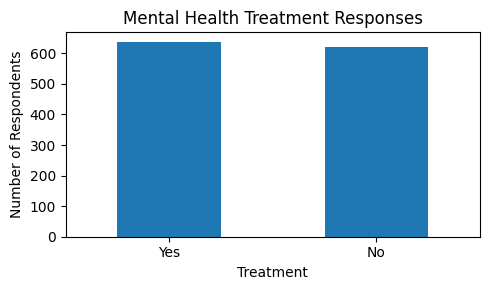

In [38]:
# Chart 1: Mental Health Treatment Distribution

treatment_counts = df["treatment"].value_counts(dropna=False)

plt.figure(figsize=(5, 3))

treatment_counts.plot(
    kind="bar"
)

plt.title("Mental Health Treatment Responses")
plt.xlabel("Treatment")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

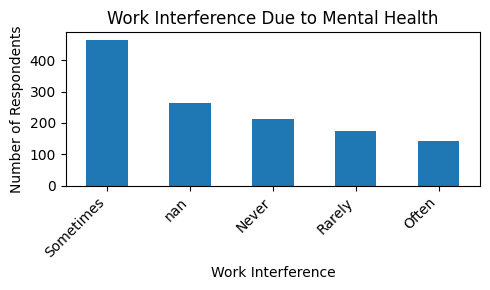

In [39]:
work_interference_counts = df["work_interfere"].value_counts(dropna=False)

plt.figure(figsize=(5, 3))
work_interference_counts.plot(kind="bar")

plt.title("Work Interference Due to Mental Health")
plt.xlabel("Work Interference")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

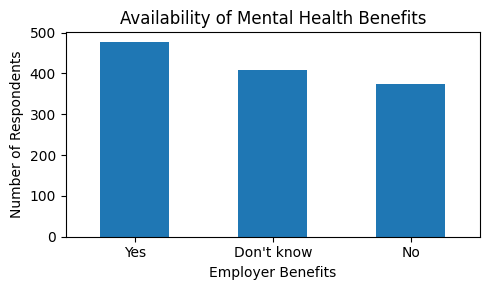

In [40]:
benefits_counts = df["benefits"].value_counts(dropna=False)

plt.figure(figsize=(5, 3))
benefits_counts.plot(kind="bar")

plt.title("Availability of Mental Health Benefits")
plt.xlabel("Employer Benefits")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

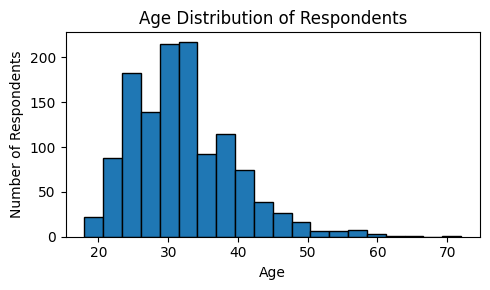

In [42]:
age_numeric = pd.to_numeric(df["Age"], errors="coerce")

valid_ages = age_numeric[
    (age_numeric >= 16) & (age_numeric <= 100)
]

plt.figure(figsize=(5, 3))
plt.hist(valid_ages, bins=20, edgecolor="black")

plt.title("Age Distribution of Respondents")
plt.xlabel("Age")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()

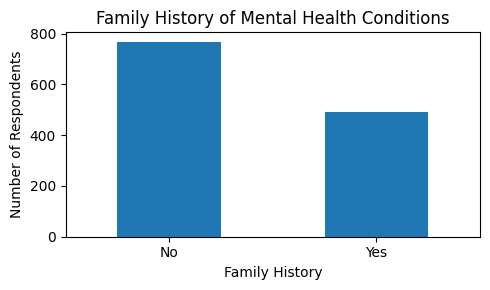

In [43]:
family_history_counts = df["family_history"].value_counts(dropna=False)

plt.figure(figsize=(5, 3))
family_history_counts.plot(kind="bar")

plt.title("Family History of Mental Health Conditions")
plt.xlabel("Family History")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Treatment Analysis by Workplace Factors

This section examines the relationship between mental health treatment and selected workplace-related factors.

The analysis considers the following variables:

- Family History
- Employer Benefits
- Remote Work
- Company Size
- Work Interference

For each factor, the number of respondents and the percentage reporting mental health treatment are calculated.

This analysis is descriptive and does not establish a causal relationship between workplace factors and mental health treatment.

In [44]:
factor_results = []

treatment = (
    df["treatment"]
    .astype("string")
    .str.strip()
    .str.lower()
)

factors = [
    "family_history",
    "benefits",
    "remote_work",
    "no_employees",
    "work_interfere"
]

for factor in factors:

    temp = pd.DataFrame({
        "Group": df[factor],
        "Treatment": treatment
    })

    temp = temp[
        temp["Treatment"].isin(["yes", "no"]) &
        temp["Group"].notna()
    ].copy()

    temp["Treatment Yes"] = (
        temp["Treatment"] == "yes"
    ).astype(int)

    grouped = (
        temp.groupby("Group", dropna=False)
        .agg(
            Respondents=("Treatment", "size"),
            Treatment_Yes=("Treatment Yes", "sum")
        )
        .reset_index()
    )

    grouped["Treatment Rate (%)"] = (
        grouped["Treatment_Yes"] /
        grouped["Respondents"] * 100
    ).round(2)

    grouped.insert(0, "Factor", factor)

    factor_results.append(grouped)

treatment_by_factor = pd.concat(
    factor_results,
    ignore_index=True
)

display(treatment_by_factor)

,Factor,Group,Respondents,Treatment_Yes,Treatment Rate (%)
0,family_history,No,767,272,35.46
1,family_history,Yes,492,365,74.19
2,benefits,Don't know,408,151,37.01
3,benefits,No,374,181,48.40
4,benefits,Yes,477,305,63.94
5,remote_work,No,883,439,49.72
6,remote_work,Yes,376,198,52.66
7,no_employees,01-May,162,91,56.17
8,no_employees,100-500,176,95,53.98
9,no_employees,26-100,289,150,51.90


## 8. Timestamp Analysis

This section examines the survey submission timestamps to understand when responses were collected.

The analysis includes:

- Converting the Timestamp column into a datetime format.
- Identifying invalid timestamps.
- Finding the earliest and latest survey submissions.
- Calculating monthly response counts.
- Calculating monthly mental health treatment rates.

This analysis focuses on survey response activity over time. It does not represent changes in individual respondents' mental health.

In [45]:
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    errors="coerce",
    utc=True
)

invalid_timestamp_count = df["Timestamp"].isna().sum()

print("Invalid timestamps:", invalid_timestamp_count)

print("Earliest timestamp:", df["Timestamp"].min())
print("Latest timestamp:", df["Timestamp"].max())

Invalid timestamps: 0
Earliest timestamp: 2014-08-27 11:29:00+00:00
Latest timestamp: 2016-02-01 23:04:00+00:00


<PROJECT_ROOT>\AppData\Local\Temp\ipykernel_77796\2758532698.py:1: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Timestamp"] = pd.to_datetime(


In [46]:
time_data = df[["Timestamp", "treatment"]].copy()

time_data = time_data.dropna(subset=["Timestamp"])

time_data["Month"] = (
    time_data["Timestamp"].dt.strftime("%Y-%m")
)

time_data["Treatment"] = (
    time_data["treatment"]
    .astype("string")
    .str.strip()
    .str.lower()
)

time_data["Valid Treatment"] = (
    time_data["Treatment"].isin(["yes", "no"])
)

time_data["Treatment Yes"] = (
    time_data["Treatment"] == "yes"
).astype(int)

monthly_analysis = (
    time_data.groupby("Month")
    .agg(
        Total_Responses=("Treatment", "size"),
        Valid_Treatment_Responses=("Valid Treatment", "sum"),
        Treatment_Yes=("Treatment Yes", "sum")
    )
    .reset_index()
)

monthly_analysis["Treatment Rate (%)"] = (
    monthly_analysis["Treatment_Yes"] /
    monthly_analysis["Valid_Treatment_Responses"] * 100
).round(2)

display(monthly_analysis)

,Month,Total_Responses,Valid_Treatment_Responses,Treatment_Yes,Treatment Rate (%)
0,2014-08,1135,1135,565,49.78
1,2014-09,47,47,24,51.06
2,2014-10,3,3,3,100.00
3,2014-11,3,3,1,33.33
4,2014-12,2,2,1,50.00
5,2015-01,1,1,1,100.00
6,2015-02,47,47,26,55.32
7,2015-04,5,5,4,80.00
8,2015-05,5,5,3,60.00
9,2015-06,1,1,1,100.00


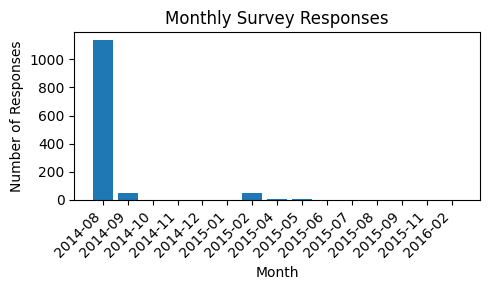

In [48]:
plt.figure(figsize=(5, 3))

plt.bar(
    monthly_analysis["Month"],
    monthly_analysis["Total_Responses"]
)

plt.title("Monthly Survey Responses")
plt.xlabel("Month")
plt.ylabel("Number of Responses")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

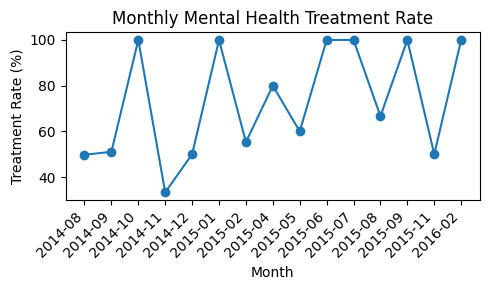

In [49]:
plt.figure(figsize=(5, 3))

plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Treatment Rate (%)"],
    marker="o"
)

plt.title("Monthly Mental Health Treatment Rate")
plt.xlabel("Month")
plt.ylabel("Treatment Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 9. Consolidated Excel Report

The results from the Data Understanding phase are consolidated into a single Excel workbook.

The workbook contains separate sheets for:

- Data Profile
- Missing Values
- Invalid Ages
- Gender Categories
- KPIs
- Treatment by Workplace Factors
- Monthly Survey Analysis

This report provides a structured overview of the dataset, its data quality, key indicators and exploratory findings.

In [50]:
data_quality_summary = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Total Missing Values",
        "Total Duplicate Rows",
        "Invalid Age Records",
        "Invalid Timestamp Records"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(invalid_age_mask.sum()),
        int(invalid_timestamp_count)
    ]
})

display(data_quality_summary)

,Metric,Value
0,Total Rows,1259
1,Total Columns,27
2,Total Missing Values,1892
3,Total Duplicate Rows,1
4,Invalid Age Records,8
5,Invalid Timestamp Records,0


In [52]:
print("=" * 60)
print("OSMI MENTAL HEALTH IN TECH SURVEY")
print("DATA UNDERSTANDING - FINAL SUMMARY")
print("=" * 60)

print(f"Dataset dimensions: {df.shape[0]} rows x {df.shape[1]} columns")

print(f"Total missing values: {df.isna().sum().sum()}")

print(f"Duplicate rows: {df.duplicated().sum()}")

print(f"Invalid age records: {invalid_age_mask.sum()}")

print(f"Invalid timestamps: {invalid_timestamp_count}")

print("\nKEY PERFORMANCE INDICATORS")
display(kpi_df)

print("\nTREATMENT ANALYSIS BY WORKPLACE FACTORS")
display(treatment_by_factor)

print("\nMONTHLY SURVEY ANALYSIS")
display(monthly_analysis)

print("\nData Understanding phase completed.")

OSMI MENTAL HEALTH IN TECH SURVEY
DATA UNDERSTANDING - FINAL SUMMARY
Dataset dimensions: 1259 rows x 27 columns
Total missing values: 1892
Duplicate rows: 1
Invalid age records: 8
Invalid timestamps: 0

KEY PERFORMANCE INDICATORS


,KPI,Percentage,Positive Responses,Valid Responses,Missing Responses
0,Treatment Rate,50.60,637,1259,0
1,Work Interference Rate,61.21,609,995,264
2,Family History Rate,39.08,492,1259,0
3,Employer Benefits Coverage,37.89,477,1259,0
4,Mental Health Consequence Concern Rate,23.19,292,1259,0



TREATMENT ANALYSIS BY WORKPLACE FACTORS


,Factor,Group,Respondents,Treatment_Yes,Treatment Rate (%)
0,family_history,No,767,272,35.46
1,family_history,Yes,492,365,74.19
2,benefits,Don't know,408,151,37.01
3,benefits,No,374,181,48.40
4,benefits,Yes,477,305,63.94
5,remote_work,No,883,439,49.72
6,remote_work,Yes,376,198,52.66
7,no_employees,01-May,162,91,56.17
8,no_employees,100-500,176,95,53.98
9,no_employees,26-100,289,150,51.90



MONTHLY SURVEY ANALYSIS


,Month,Total_Responses,Valid_Treatment_Responses,Treatment_Yes,Treatment Rate (%)
0,2014-08,1135,1135,565,49.78
1,2014-09,47,47,24,51.06
2,2014-10,3,3,3,100.00
3,2014-11,3,3,1,33.33
4,2014-12,2,2,1,50.00
5,2015-01,1,1,1,100.00
6,2015-02,47,47,26,55.32
7,2015-04,5,5,4,80.00
8,2015-05,5,5,3,60.00
9,2015-06,1,1,1,100.00



Data Understanding phase completed.
